# Denoising Autoencoder on Fashion-MNIST — walkthrough

Interactive version of `src/denoising_autoencoder.py`. A fully connected autoencoder learns to recover clean 28×28 clothing images from inputs buried in Gaussian noise (σ = 100/255, input PSNR ≈ 8 dB).

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt, keras
sys.path.append('../src')
import denoising_autoencoder as dae
%matplotlib inline

dae.make_reproducible()
x_train, y_train, x_test, y_test = dae.load_data()
print('train', x_train.shape, ' test', x_test.shape)

train (48000, 28, 28)  test (10000, 28, 28)


## 1. The task: noisy input → clean target

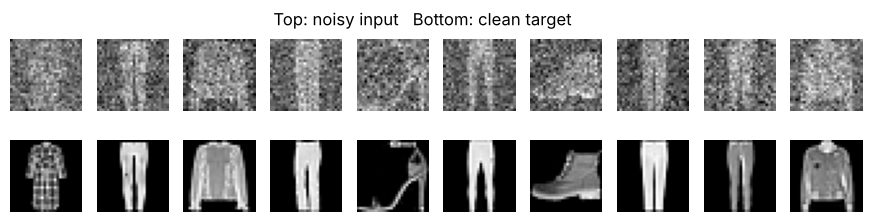

In [2]:
fig, axes = plt.subplots(2, 10, figsize=(11, 2.4))
for i in range(10):
    axes[0, i].imshow(x_train[i], cmap='gray'); axes[1, i].imshow(y_train[i], cmap='gray')
    for r in range(2): axes[r, i].axis('off')
fig.suptitle('Top: noisy input   Bottom: clean target'); plt.show()

## 2. Model

`Flatten → Normalization (per-pixel standardisation) → Dense(300, ReLU) → Dense(784, linear) → Reshape(28, 28)`

* **Loss:** MSE  · **Optimiser:** SGD + Nesterov momentum (0.9), lr = 0.1  · **Regularisation:** L2 (1e-5) on all dense kernels
* The 300-unit bottleneck forces the network to keep only structure that is common across garments; pixel-independent noise cannot be represented compactly, so it is discarded.

In [3]:
dae.make_reproducible()
model = dae.build_model(x_train, hidden_units=[300], learning_rate=0.1)
model.summary()

Model: "denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 784)            │         1,569 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 784)            │       235,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 473,053 (1.80 MB)

 Trainable params: 471,484 (1.80 MB)

 Non-trainable params: 1,569 (6.13 KB)

## 3. Train

Epoch 1/20


750/750 - 3s - 4ms/step - loss: 0.1159 - learning_rate: 0.1000


Epoch 2/20


750/750 - 3s - 4ms/step - loss: 0.0454 - learning_rate: 0.1000


Epoch 3/20


...

750/750 - 3s - 3ms/step - loss: 0.0168 - learning_rate: 0.1000


Epoch 19/20


750/750 - 3s - 3ms/step - loss: 0.0166 - learning_rate: 0.1000


Epoch 20/20


750/750 - 3s - 4ms/step - loss: 0.0164 - learning_rate: 0.1000


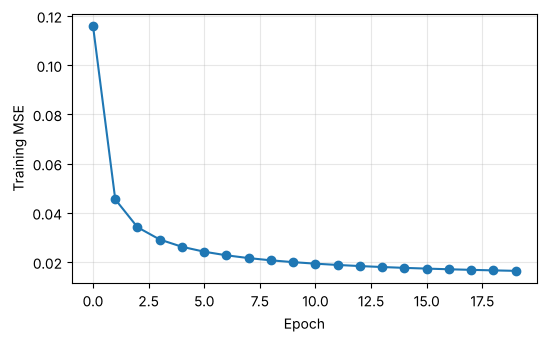

In [4]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=3, min_lr=1e-4)
dae.make_reproducible()
history = model.fit(x_train, y_train, batch_size=64, epochs=20, shuffle=True, verbose=2, callbacks=[reduce_lr])

plt.figure(figsize=(6, 3.5)); plt.plot(history.history['loss'], marker='o')
plt.xlabel('Epoch'); plt.ylabel('Training MSE'); plt.grid(alpha=.3); plt.show()

## 4. Evaluate

In [5]:
pred_test = model.predict(x_test, verbose=0)
noisy_mse, test_mse = dae.mse(x_test, y_test), dae.mse(pred_test, y_test)
print(f'Noisy input : MSE {noisy_mse:.4f} | PSNR {dae.psnr(noisy_mse):.1f} dB')
print(f'Denoised    : MSE {test_mse:.4f} | PSNR {dae.psnr(test_mse):.1f} dB')
print(f'Improvement : {noisy_mse/test_mse:.1f}x lower MSE, +{dae.psnr(test_mse)-dae.psnr(noisy_mse):.1f} dB')

Noisy input : MSE 0.1538 | PSNR 8.1 dB
Denoised    : MSE 0.0160 | PSNR 17.9 dB
Improvement : 9.6x lower MSE, +9.8 dB


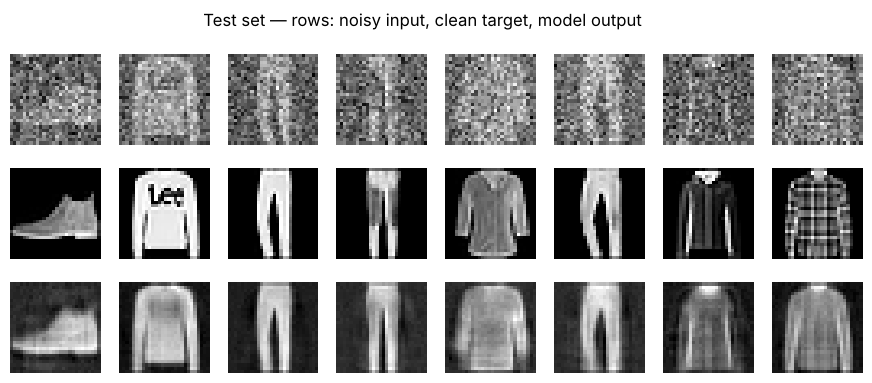

In [6]:
fig, axes = plt.subplots(3, 8, figsize=(11, 4.2))
for i in range(8):
    for r, img in enumerate((x_test[i], y_test[i], pred_test[i])):
        axes[r, i].imshow(img, cmap='gray'); axes[r, i].axis('off')
fig.suptitle('Test set — rows: noisy input, clean target, model output'); plt.show()

## 5. Probing the decoder with pure noise

Feeding the trained network inputs that contain **no garment at all** shows what it has learned to "expect": outputs collapse to blurry, average garment-like silhouettes. This is the key limitation of a plain autoencoder for generation — its latent space is not regularised, which is what motivates the variational autoencoder (VAE).

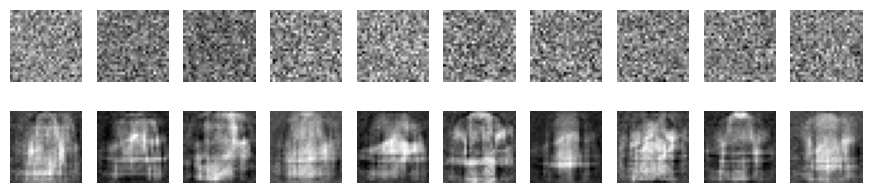

In [7]:
fig, axes = plt.subplots(2, 10, figsize=(11, 2.4))
import cv2
for i in range(10):
    img = cv2.resize(np.random.normal(0, 10, (2, 4)), (28, 28), interpolation=cv2.INTER_CUBIC)
    img = (img + np.random.normal(0, 300, (28, 28))).reshape(1, 28, 28) / 255
    axes[0, i].imshow(img[0], cmap='gray'); axes[1, i].imshow(model.predict(img, verbose=0)[0], cmap='gray')
    for r in range(2): axes[r, i].axis('off')
plt.show()